# 06 新增基线MRI逐文件技术质控

范围限定于临床版本更新后追加的4组基线检查、1,584个DICOM。需要恢复追加包或运行下载脚本；不把其余40,801个已归档文件描述为完成本轮检查。空白RN不变为阴性，技术通过不等于病灶诊断或临床图像质量通过。

In [1]:
from pathlib import Path
import sys,json,runpy
import pandas as pd
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
summary=runpy.run_path(str(ROOT/'scripts/audit_additional_imaging.py'))['run']()
assert summary['dicom_files']==1584
assert summary['integrity_verified_files']==summary['pixel_decodable_files']==1584

{
  "scope": "all files in four added baseline studies only",
  "studies": 4,
  "dicom_files": 1584,
  "series_uid_groups": 28,
  "series_directories": 28,
  "integrity_verified_files": 1584,
  "pixel_decodable_files": 1584,
  "nonfinite_pixel_arrays": 0,
  "constant_pixel_arrays": 0,
  "date_mismatch_files": 0,
  "duplicate_sop_files": 0,
  "regular_geometry_stacks": 28,
  "technical_pass_stacks": 28,
  "t2_flair_metadata_candidates": 4,
  "t1_flair_names_not_t2_flair": 3,
  "derived_or_projection_groups": 8,
  "spacing_tag_position_mismatch_groups": 3,
  "t2_flair_candidates_with_interslice_gap": 4,
  "contrast_bolus_tag_populated_files": 0,
  "baseline_lesion_candidates_in_added_studies": 7,
  "baseline_mask_candidates": 1,
  "grid_equivalent_masks": 1,
  "engineering_tolerances": {
    "direction_or_spacing_abs": 0.0001,
    "duplicate_plane_mm": 0.001,
    "plane_step_abs_mm": 0.05,
    "plane_step_relative": 0.01,
    "affine_residual_mm": 0.1,
    "grid_corner_voxels": 0.001
  }

## 序列与空间坐标

按SeriesInstanceUID分组。使用ImagePositionPatient在切片法向的投影排序，不使用文件名或InstanceNumber；仿射保留平面内位移。DICOM的LPS坐标转为NIfTI使用的RAS坐标。工程容差见报告，不代表临床可接受阈值。常规序列中的层间隙与不规则缺层分别报告。

In [2]:
s=pd.read_csv(ROOT/'data/processed/additional_dicom_series_qc.csv')
print(s[['patient_id','series_name','files','slice_step_mm','technical_stack_pass','spacing_tag_position_mismatch','t2_flair_metadata_candidate','derived_or_projection_hint']].to_string(index=False))
assert s.files.sum()==1584
print('Spacing tag discrepancies:',summary['spacing_tag_position_mismatch_groups'])
print('T2-FLAIR candidates with slice gaps:',summary['t2_flair_candidates_with_interslice_gap'])

 patient_id       series_name  files  slice_step_mm  technical_stack_pass  spacing_tag_position_mismatch  t2_flair_metadata_candidate  derived_or_projection_hint
      20001         3D_T1_TFE    160       1.000002                     1                              0                            0                           0
      20001         COR_SE_T1     40       3.300000                     1                              0                            0                           0
      20001      SAG_FLAIR_T1     24       4.400000                     1                              0                            0                           0
      20001      TRA_FLAIR_T2     30       4.400000                     1                              0                            1                           0
      20001         TRA_SE_T1     40       3.300001                     1                              0                            0                           0
      20001        TRA_TSE_T

## 分割与影像网格匹配

追加检查对应7个病灶基线候选，只有40093_L3有同期公开掩膜。比较完整体积8个角点在影像网格中的映射，仅当其为有符号轴置换且误差≤0.001体素时认可网格等价。这里不做插值或配准。397个目标体素来自既有分割，不是RN诊断标签。

In [3]:
m=pd.read_csv(ROOT/'data/processed/additional_baseline_mask_alignment.csv')
print(m[['lesion_key','study_date_code','baseline_mask_available','alignment_status','max_corner_error_voxels','target_voxels_inside_image']].to_string(index=False))
x=m[m.grid_equivalent==1]
assert len(x)==1
assert x.iloc[0].target_voxels_inside_image==397
assert m.use_for_model.sum()==0

lesion_key  study_date_code  baseline_mask_available                 alignment_status  max_corner_error_voxels  target_voxels_inside_image
  20001_L1         19000810                        0 no_contemporaneous_baseline_mask                      NaN                         NaN
  20013_L1         19000130                        0 no_contemporaneous_baseline_mask                      NaN                         NaN
  20013_L2         19000130                        0 no_contemporaneous_baseline_mask                      NaN                         NaN
  20013_L3         19000130                        0 no_contemporaneous_baseline_mask                      NaN                         NaN
  20013_L4         19000130                        0 no_contemporaneous_baseline_mask                      NaN                         NaN
  20020_L1         19000216                        0 no_contemporaneous_baseline_mask                      NaN                         NaN
  40093_L3         19010113

## 分割轮廓叠加图

图中轮廓使用同一网格的整数索引翻转，未修改原始MRI或掩膜。图像展示用于技术复核，不构成RN诊断或正式临床质量判定。

In [4]:
from IPython.display import Image,display
display(Image(filename=str(ROOT/'outputs/imaging-qc-20261028/40093_L3_mask_overlay.png')))

## 解释与后续

4组检查均有T2-FLAIR名称候选；3个T1-FLAIR不混用；8个投影/重建序列单独标识，不作为独立原始采集。所有文件的ContrastBolusAgent均未填写，序列名称和本图显示的信号不能确定注射时间。T1与T2-FLAIR配准仍未实施。下一步扩展原归档基线序列的逐文件质控，同时继续核实公开结局证据；125条未知结局及0条已核实阴性保持不变。

方法依据：[DICOM Image Plane Module](https://dicom.nema.org/medical/dicom/2026c/output/chtml/part03/sect_C.7.6.2.html)、[NiBabel DICOM orientation](https://nipy.org/nibabel/dicom/dicom_orientation.html)、[NiBabel coordinate systems](https://nipy.org/nibabel/coordinate_systems.html)、[pydicom pixel data](https://pydicom.github.io/pydicom/stable/guides/user/working_with_pixel_data.html)。

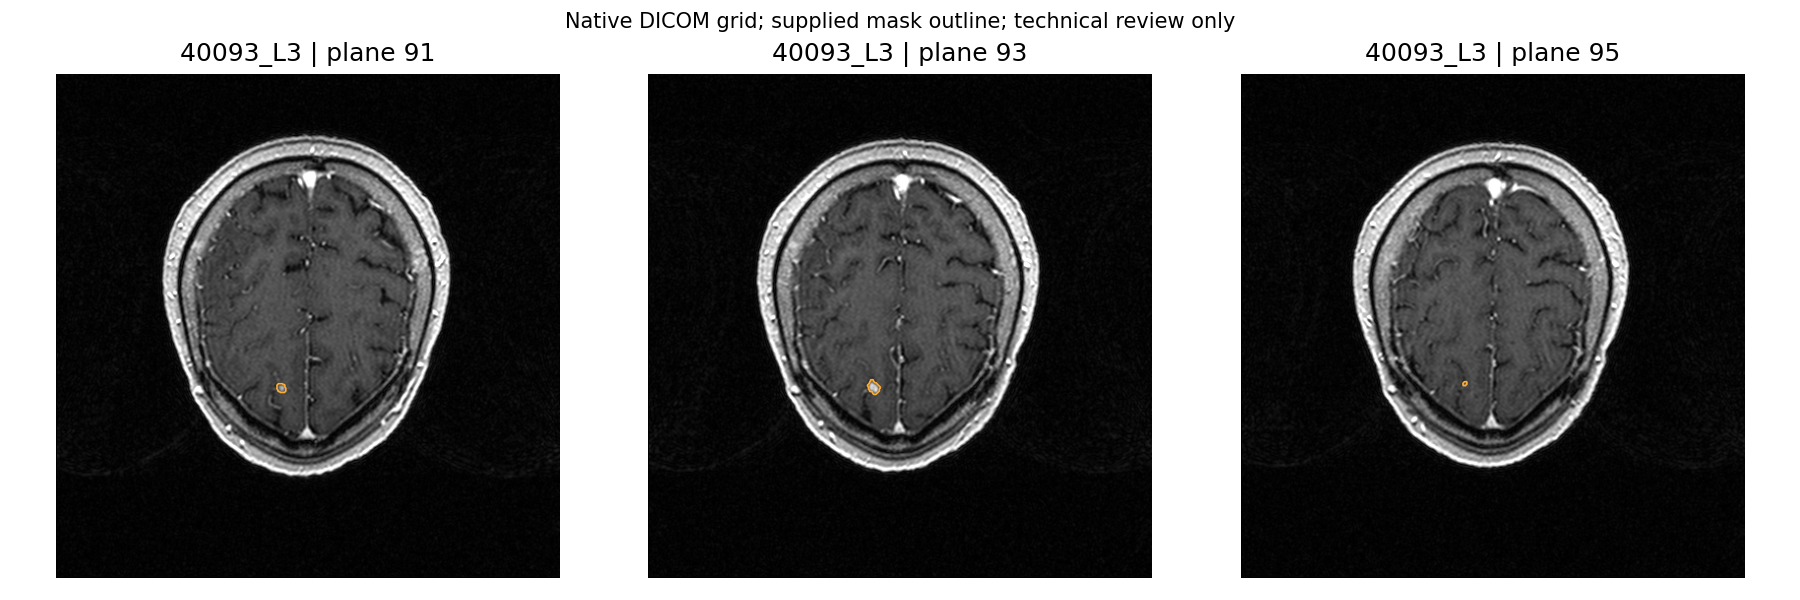

Technical audit complete for added studies; full cohort image QC and endpoint adjudication remain pending.


In [5]:
c=pd.read_csv(ROOT/'data/processed/clinical_current.csv')
assert c.rn_time_day.isna().sum()==125
assert c.verified_non_event.sum()==0
assert summary['models_fitted'] is False
assert summary['full_selected_mri_qc_complete'] is False
print('Technical audit complete for added studies; full cohort image QC and endpoint adjudication remain pending.')